# Exploratory Data Analysis (EDA): Pola Peminjaman & Prediksi Keterlambatan Buku Perpustakaan
**Tugas Ujian Tengah Semester (UTS) — Mata Kuliah Data Science (PSIKS2W002)**
* **Nama Mahasiswa:** Arif Tri Wicaksono
* **NIM:** 26MA4D015
* **Program Studi:** Magister Ilmu Komputer, Universitas Amikom Purwokerto
* **Dosen Pengampu:** Giat Karyono, M.Kom.

---

## Bab 1: Pendahuluan & Memahami Masalah (*Understanding the Problem*)
* **Latar Belakang & Tujuan Utama:** Mengeksplorasi pola sirkulasi peminjaman buku perpustakaan (`library_data.csv`) dan mengidentifikasi faktor utama pemicu keterlambatan pengembalian (`overdue_status`).
* **Tipe Masalah:** *Supervised Learning* — Klasifikasi Biner (`0` = Tepat Waktu, `1` = Terlambat).
* **Metrik Keberhasilan Utama:** *Recall* (meminimalkan kasus keterlambatan yang terlewat) dan *F1-Score*.

## Bab 2 & 3: Memuat & Memeriksa Data (*Understanding, Importing & Inspecting Data*)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Pengaturan gaya visualisasi
sns.set_theme(style="whitegrid")

# 3.1 Memuat dataset
df = pd.read_csv('library_data.csv')
print("Dimensi Dataset (Baris, Kolom):", df.shape)
df.head()

Dimensi Dataset (Baris, Kolom): (1000, 8)


,user_id,book_id,borrow_date,return_date,reservation_status,overdue_status,user_role,book_category
0,d166c2c3-a24a-482f-bd50-c1c2b115aea4,ed728782-79ea-4cec-ad23-236e745caff6,2023-03-13,2023-03-29,True,1,student,non-fiction
1,902f3b25-7d14-4943-8aff-27b3eac9a7aa,02903451-e16b-49e3-8afc-69cba817208d,2022-04-02,2022-04-07,True,0,student,art
2,6cee8789-3fbe-4b35-bcf5-a891484adefe,ba2eacff-aa53-4950-bd8d-5fe7d8a4db49,2023-06-06,2023-06-08,True,0,faculty,history
3,588e367e-1a23-41dc-a8a0-127a482c2e6a,6a350522-8b9a-4581-aaa8-48e8ec90d997,2022-10-05,2022-10-24,False,1,student,non-fiction
4,3d15c259-fced-4210-9d6c-28292e9ded79,1bcb4fa7-7e2c-41f9-8d6a-73e7c06db0ce,2020-07-04,2020-07-09,False,0,student,fiction


In [10]:
# 3.2 Inspeksi tipe data dan informasi umum
print("--- INFORMASI TIPE DATA ---")
df.info()

print("\n--- RINGKASAN STATISTIK AWAL ---")
display(df.describe(include='all'))

--- INFORMASI TIPE DATA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   user_id             1000 non-null   object
 1   book_id             1000 non-null   object
 2   borrow_date         1000 non-null   object
 3   return_date         1000 non-null   object
 4   reservation_status  1000 non-null   bool  
 5   overdue_status      1000 non-null   int64 
 6   user_role           1000 non-null   object
 7   book_category       1000 non-null   object
dtypes: bool(1), int64(1), object(6)
memory usage: 55.8+ KB

--- RINGKASAN STATISTIK AWAL ---


,user_id,book_id,borrow_date,return_date,reservation_status,overdue_status,user_role,book_category
count,1000,1000,1000,1000,1000,1000.000000,1000,1000
unique,1000,1000,765,790,2,NaN,3,5
top,d166c2c3-a24a-482f-bd50-c1c2b115aea4,ed728782-79ea-4cec-ad23-236e745caff6,2023-07-24,2020-03-09,True,NaN,student,art
freq,1,1,4,4,507,NaN,345,208
mean,NaN,NaN,NaN,NaN,NaN,0.627000,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,0.483844,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN


## Bab 4: Penanganan Data yang Hilang (*Handling Missing Data*) & Kualitas Data

In [11]:
# 4.1 Identifikasi Missing Values dan Data Duplikat
missing_df = pd.DataFrame({
    'Jumlah Missing': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df)) * 100
})
print("--- CEK MISSING VALUES ---")
display(missing_df)
print("Jumlah baris duplikat:", df.duplicated().sum())

--- CEK MISSING VALUES ---


,Jumlah Missing,Persentase (%)
user_id,0,0.0
book_id,0,0.0
borrow_date,0,0.0
return_date,0,0.0
reservation_status,0,0.0
overdue_status,0,0.0
user_role,0,0.0
book_category,0,0.0


Jumlah baris duplikat: 0


## Bab 5 & 6: Eksplorasi Karakteristik Data & Transformasi (*Feature Engineering*)

In [12]:
# 6.4 Pembuatan Fitur Baru (Feature Engineering)
df['borrow_date'] = pd.to_datetime(df['borrow_date'])
df['return_date'] = pd.to_datetime(df['return_date'])

# Ekstraksi durasi peminjaman dalam hari
df['loan_duration'] = (df['return_date'] - df['borrow_date']).dt.days
df['borrow_month'] = df['borrow_date'].dt.month
df['is_weekend_borrow'] = df['borrow_date'].dt.dayofweek.isin([5, 6]).astype(int)

# Binning durasi pinjam
df['duration_category'] = pd.cut(df['loan_duration'], bins=[0, 7, 14, 21], labels=['Pendek', 'Sedang', 'Lama'])

# 5.1 & 5.2 Statistik Deskriptif, Skewness, dan Kurtosis
print("--- STATISTIK DURASI PEMINJAMAN (HARI) ---")
print(df['loan_duration'].describe())
print(f"Skewness: {skew(df['loan_duration']):.4f}")
print(f"Kurtosis: {kurtosis(df['loan_duration']):.4f}")

--- STATISTIK DURASI PEMINJAMAN (HARI) ---
count    1000.000000
mean       10.223000
std         5.753466
min         1.000000
25%         5.000000
50%        10.000000
75%        15.000000
max        20.000000
Name: loan_duration, dtype: float64
Skewness: 0.0648
Kurtosis: -1.1994


In [13]:
# 6.2 & 6.3 Scaling & Categorical Encoding
scaler_minmax = MinMaxScaler()
df['loan_duration_minmax'] = scaler_minmax.fit_transform(df[['loan_duration']])

scaler_std = StandardScaler()
df['loan_duration_std'] = scaler_std.fit_transform(df[['loan_duration']])

# One-Hot Encoding untuk variabel kategorikal nominal
df_encoded = pd.get_dummies(df, columns=['user_role', 'book_category'], drop_first=False)
df_encoded['reservation_status'] = df_encoded['reservation_status'].astype(int)

print("Dimensi setelah Encoding & Feature Engineering:", df_encoded.shape)
df_encoded.head(3)

Dimensi setelah Encoding & Feature Engineering: (1000, 20)


,user_id,book_id,borrow_date,return_date,reservation_status,overdue_status,loan_duration,borrow_month,is_weekend_borrow,duration_category,loan_duration_minmax,loan_duration_std,user_role_faculty,user_role_staff,user_role_student,book_category_art,book_category_fiction,book_category_history,book_category_non-fiction,book_category_science
0,d166c2c3-a24a-482f-bd50-c1c2b115aea4,ed728782-79ea-4cec-ad23-236e745caff6,2023-03-13,2023-03-29,1,1,16,3,0,Lama,0.789474,1.004593,False,False,True,False,False,False,True,False
1,902f3b25-7d14-4943-8aff-27b3eac9a7aa,02903451-e16b-49e3-8afc-69cba817208d,2022-04-02,2022-04-07,1,0,5,4,1,Pendek,0.210526,-0.908255,False,False,True,True,False,False,False,False
2,6cee8789-3fbe-4b35-bcf5-a891484adefe,ba2eacff-aa53-4950-bd8d-5fe7d8a4db49,2023-06-06,2023-06-08,1,0,2,6,0,Pendek,0.052632,-1.429941,True,False,False,False,False,True,False,False


## Bab 7: Visualisasi Hubungan Data (*Univariate, Bivariate & Multivariate*)

/tmp/ipykernel_3375/1820430909.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df, x='overdue_status', ax=axes[0], palette=['#4E79A7', '#E15759'])
/tmp/ipykernel_3375/1820430909.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.countplot(data=df, x='user_role', order=['student', 'staff', 'faculty'], ax=axes[1], palette='Blues_d')
/tmp/ipykernel_3375/1820430909.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.countplot(data=df, x='book_category', order=df['book_category'].value_counts().index, ax=axes[2], palette='viridis'

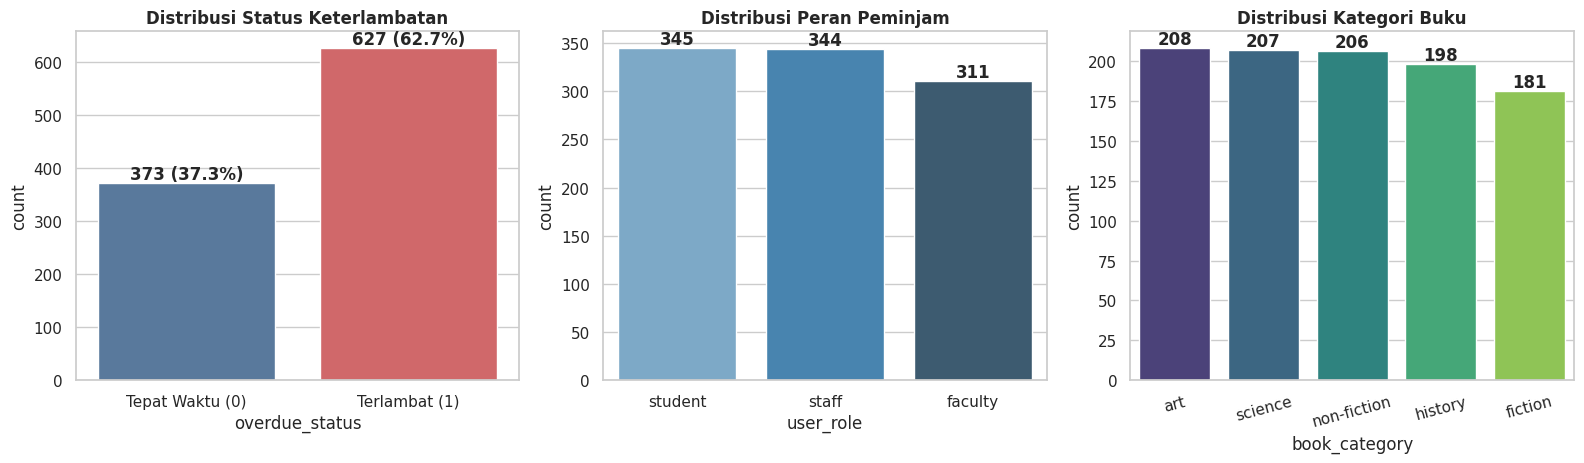

In [14]:
# 7.1 Visualisasi Univariat
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax1 = sns.countplot(data=df, x='overdue_status', ax=axes[0], palette=['#4E79A7', '#E15759'])
axes[0].set_title('Distribusi Status Keterlambatan', fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Tepat Waktu (0)', 'Terlambat (1)'])
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                 (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

ax2 = sns.countplot(data=df, x='user_role', order=['student', 'staff', 'faculty'], ax=axes[1], palette='Blues_d')
axes[1].set_title('Distribusi Peran Peminjam', fontweight='bold')
for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

ax3 = sns.countplot(data=df, x='book_category', order=df['book_category'].value_counts().index, ax=axes[2], palette='viridis')
axes[2].set_title('Distribusi Kategori Buku', fontweight='bold')
axes[2].tick_params(axis='x', rotation=15)
for p in ax3.patches:
    ax3.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

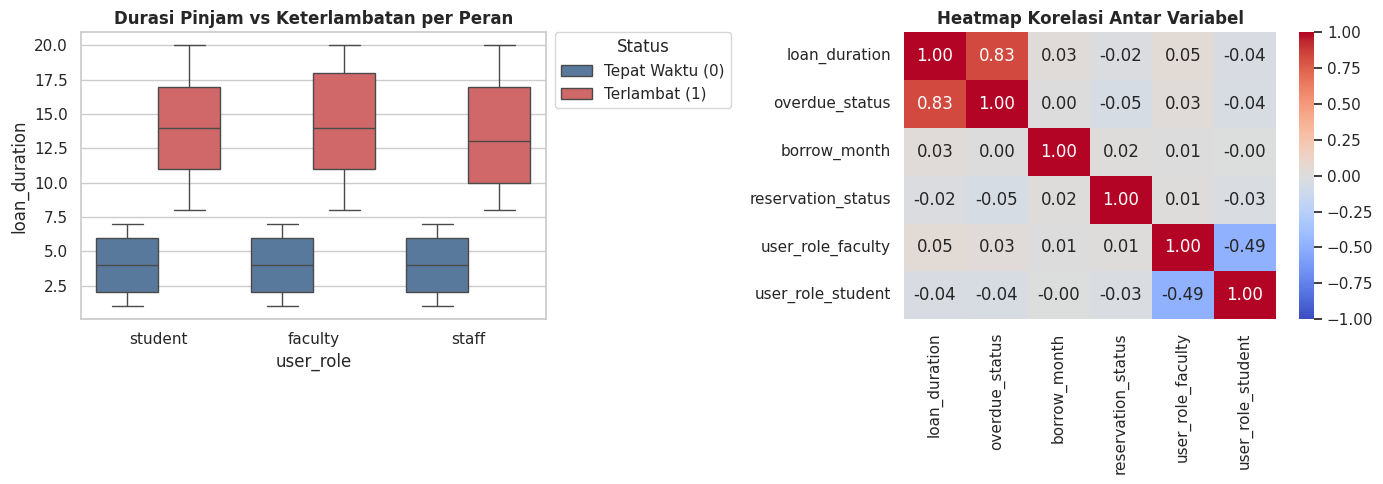

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Pastikan variabel 'df' dan 'df_encoded' sudah ada dari cell sebelumnya.
# Jika belum, pastikan Anda meload dataset Anda di sini terlebih dahulu, contoh:
# df = pd.read_csv('nama_file_anda.csv')
# df_encoded = ...

# 7.2 & 7.3 Bivariate Analysis & Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='user_role', y='loan_duration', hue='overdue_status', ax=axes[0], palette=['#4E79A7', '#E15759'])
axes[0].set_title('Durasi Pinjam vs Keterlambatan per Peran', fontweight='bold')
handles, _ = axes[0].get_legend_handles_labels()

# Memindahkan legend ke luar/atas agar tidak menutupi whisker
axes[0].legend(handles, ['Tepat Waktu (0)', 'Terlambat (1)'], title='Status',
               bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

corr_cols = ['loan_duration', 'overdue_status', 'borrow_month', 'reservation_status', 'user_role_faculty', 'user_role_student']
sns.heatmap(df_encoded[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Heatmap Korelasi Antar Variabel', fontweight='bold')

plt.tight_layout()
plt.show()

## Bab 8: Penanganan Pencilan (*Handling Outliers*)

Q1: 5.0, Q3: 15.0, IQR: 10.0
Batas Bawah: -10.0 hari | Batas Atas: 30.0 hari
Jumlah Pencilan Terdeteksi: 0 baris


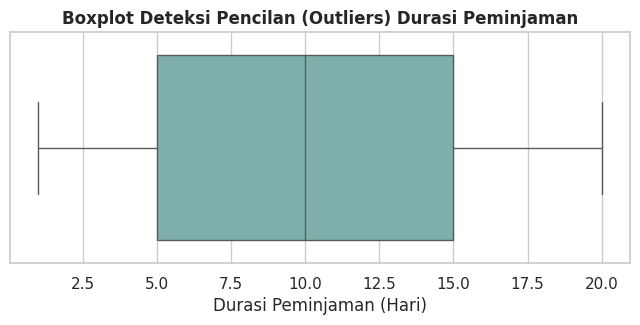

In [16]:
# 8.1 Deteksi Outliers dengan Metode IQR
Q1 = df['loan_duration'].quantile(0.25)
Q3 = df['loan_duration'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['loan_duration'] < lower_bound) | (df['loan_duration'] > upper_bound)]
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Batas Bawah: {lower_bound} hari | Batas Atas: {upper_bound} hari")
print(f"Jumlah Pencilan Terdeteksi: {len(outliers)} baris")

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['loan_duration'], color='#76B7B2')
plt.title('Boxplot Deteksi Pencilan (Outliers) Durasi Peminjaman', fontweight='bold')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.show()

## Bab 9: Kesimpulan & Rekomendasi Model (*Communicate Findings & Insights*)
1. **Tingkat Keterlambatan Tinggi (62,7%):** Mayoritas peminjaman melewati batas waktu standar 7 hari (korelasi $r = 0,83$ antara `loan_duration` dan `overdue_status`).
2. **Segmen Risiko:** Kelompok *faculty* (64,63%) dan kategori buku *Science* (66,18%) memiliki tingkat keterlambatan tertinggi.
3. **Rekomendasi Model:** Menggunakan **Random Forest Classifier** atau **XGBoost Classifier** pada tahap pemodelan prediktif berikutnya.